# Mô hình chốt: từ dữ liệu gốc đến kết quả, từng bước

**Bài toán.** Đầu mỗi năm Y (1983–2020), đoán lãi năm Y của khoảng 26.000 chiến lược kế toán (Accounting EW, Chen & Dim), rồi mua top 1/5/10% chiến lược tốt nhất. So với **baseline notebook B** và **EB** của paper.

**Kiến trúc so với baseline:**
```
                 BASELINE (notebook B)                MÔ HÌNH CHỐT
đầu vào          128 tháng lãi                        128 tháng lãi, nhân dấu (chiến lược lỗ thì làm ngược)
encoder          FinCast → [4 × 1280]                 FinCast → [4 × 1280] → PCA → [4 × 16]
chuỗi            Bi-LSTM                              LayerNorm → Bi-LSTM                            (giữ nguyên)
attention        gộp 4 đoạn                           gộp 4 đoạn                                     (giữ nguyên)
so sánh          (không có)                           ISAB: so chiến lược với cả năm                 ← MỚI
đầu ra           ghép t-stat, mean → FC → 1 số        ghép t-stat, mean → FC → 1 số                  (giữ nguyên)
mạng đoán        lãi năm sau                          Sharpe năm sau − Sharpe TB năm − nền |t|       ← MỚI
loss             MSE                                  Huber × trọng số năm (Holen)                   ← MỚI
học              1 lần, cả tập                        lại mỗi năm; mỗi bước = một năm                ← MỚI
```
Mô hình chốt = **seed 1** (chọn bằng dev muộn 1995–2004 trong 6 seed). Paper cho từng thay đổi: `docs/5_FINAL_MODEL_VS_BASELINE.md`, mục 2; PDF ở `docs/papers/`.

**Mã nguồn** (`code/`): `data.py` (Bước 1–4) · `model.py` (Bước 8, kiến trúc từng khối) · `train.py` (Bước 5–8) · `evaluate.py` (Bước 9–10) · `run.py` (học 6 seed, lưu checkpoint mỗi năm).

Ví dụ xuyên suốt: **chiến lược 18144, dự báo năm 2000**. Mỗi bước: **Ý tưởng → Khái niệm, công thức → Dữ liệu vào → Tính → Ra**.

In [1]:
import os, sys, warnings
from pathlib import Path
CODE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data.py").exists() or (p / "code" / "data.py").exists())
CODE = CODE if (CODE / "data.py").exists() else CODE / "code"
sys.path.insert(0, str(CODE)); os.chdir(CODE); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import data, model, train, evaluate as ev
pd.set_option("display.width", 200); np.set_printoptions(linewidth=200, suppress=True)
EX_ID, EX_Y = 18144, 2000
BEST_SEED = 1   # seed của mô hình chốt: seed có Sharpe dev muộn (1995–2004) cao nhất trong 6 seed (bảng ở Bước 10)
print("thư mục code:", CODE, "| GPU:", torch.cuda.get_device_name(0))

thư mục code: /home/phongndh/Documents/Paper/code | GPU: NVIDIA GeForce RTX 5060 Ti


## Bước 1. Dữ liệu gốc → ma trận lãi

**Ý tưởng:** đưa file lãi từng tháng về bảng: mỗi chiến lược một hàng, mỗi tháng một cột.

**Khái niệm:**
- **Chiến lược long–short:** mua một nhóm cổ phiếu, bán khống nhóm khác. **Lãi tháng** = lãi nhóm mua − lãi nhóm bán (%).
- **NaN:** tháng chưa có dữ liệu.
- Vị trí cột của tháng = (năm − 1960) × 12 + (tháng − 1).

**Vào:** `data_raw/DataMinedLongShortReturnsEW.csv` (signalid, year, month, ret, nstock). **Ra:** ma trận [số chiến lược × số tháng].

In [2]:
raw = pd.read_csv(data.RAW / "DataMinedLongShortReturnsEW.csv", nrows=3)
print("VÀO: 3 dòng đầu của CSV gốc"); display(raw)
ids, wide = data.load_returns()
print(f"RA: ma trận {wide.shape[0]:,} chiến lược × {wide.shape[1]} tháng (1/1960–12/2022); ô NaN: {np.isnan(wide).mean():.0%}")
r = int(np.where(ids == EX_ID)[0][0]); col = (EX_Y - data.BASE_YEAR) * 12
print(f"tháng 1/2000 nằm ở cột ({EX_Y} - 1960) × 12 + 0 = {col}")
display(pd.DataFrame(wide[[r]][:, col - 3:col + 3].round(2), index=[EX_ID], columns=["1999-10", "1999-11", "1999-12", "2000-01", "2000-02", "2000-03"]))

VÀO: 3 dòng đầu của CSV gốc
RA: ma trận 29,314 chiến lược × 756 tháng (1/1960–12/2022); ô NaN: 26%
tháng 1/2000 nằm ở cột (2000 - 1960) × 12 + 0 = 480


,signalid,year,month,ret,nstock
0,1,1990,7,1.542175,3160
1,1,1990,8,0.476569,3131
2,1,1990,9,0.274472,3116


,1999-10,1999-11,1999-12,2000-01,2000-02,2000-03
18144,-5.5,-10.3,-7.88,-7.43,-21.139999,2.64


## Bước 2. Tóm tắt 20 năm quá khứ, và đáp án

**Ý tưởng:** đứng cuối năm 1999, nhìn lại 240 tháng để đánh giá chiến lược tốt cỡ nào và có chắc không; ghi lãi thật năm 2000 làm đáp án (lúc dự báo chưa biết).

**Khái niệm, công thức** ($r_t$ = lãi tháng t, $n$ = số tháng có dữ liệu):

| Khái niệm | Công thức | Ý nghĩa |
|---|---|---|
| Lãi trung bình $m$ | $\frac{1}{n}\sum r_t$ | trung bình mỗi tháng lãi bao nhiêu % |
| Độ dao động $s$ | $\sqrt{\frac{1}{n}\sum (r_t-m)^2}$ | lãi lệch khỏi trung bình bao nhiêu (rủi ro) |
| Sai số chuẩn | $s/\sqrt{n}$ | trung bình có thể sai bao nhiêu chỉ vì may |
| **t-stat** | $m \div (s/\sqrt{n})$ | lãi gấp mấy lần sai số; \|t\| lớn → khó là may |
| Đáp án $y$ | TB 12 tháng năm Y | lãi thật năm Y |

Chỉ giữ chiến lược có ≥ 36 tháng quá khứ và đủ 12 tháng năm Y.

In [3]:
x = wide[r, col - 240:col]; y12 = wide[r, col:col + 12]; n = np.isfinite(x).sum()
print("VÀO: 240 tháng 1980–1999:", np.round(x[:6], 2), "…", np.round(x[-6:], 2))
print("     12 tháng năm 2000:   ", np.round(y12, 2))
m = np.nanmean(x); s = np.nanstd(x); se = s / np.sqrt(n); t = m / se
print(f"\nTÍNH: m = {np.nansum(x):.2f} / {n} = {m:.4f}")
print(f"      s = sqrt({np.nansum((x - m) ** 2):.1f} / {n}) = {s:.4f}")
print(f"      sai số chuẩn = {s:.4f} / sqrt({n}) = {se:.4f};   t = {m:.4f} / {se:.4f} = {t:.2f}")
print(f"      đáp án y = {y12.sum():.2f} / 12 = {y12.mean():.4f}")
T = data.load_table(); yr = T.oos_year.values
EX = int(np.where((T.signalid == EX_ID) & (yr == EX_Y))[0][0])
print(f"\nRA: bảng {T.shape[0]:,} dòng (chiến lược, năm 1966–2020); năm 2000 có {(yr == EX_Y).sum():,} chiến lược")
display(T.drop(columns="eb").iloc[[EX, EX - 1, EX + 2]].round(4))

VÀO: 240 tháng 1980–1999: [ 0.03  1.62 -5.62  2.59  1.12  1.73] … [ -1.26  -4.82  -4.75  -5.5  -10.3   -7.88]
     12 tháng năm 2000:    [ -7.43 -21.14   2.64   1.2    0.51  -5.14  -0.31  -5.22  -0.61   0.58   0.93   5.22]

TÍNH: m = -300.65 / 240 = -1.2527
      s = sqrt(943.1 / 240) = 1.9823
      sai số chuẩn = 1.9823 / sqrt(240) = 0.1280;   t = -1.2527 / 0.1280 = -9.79
      đáp án y = -28.76 / 12 = -2.3967

RA: bảng 1,189,707 dòng (chiến lược, năm 1966–2020); năm 2000 có 25,603 chiến lược


,signalid,oos_year,sgn,mean_is,sd_is,tstat,nobs,y
655588,18144,2000,-1.0,-1.2527,1.9823,-9.7901,240,2.3967
655587,18143,2000,-1.0,-1.0269,1.8627,-8.5402,240,0.7542
655590,18146,2000,-1.0,-0.3989,3.1326,-1.9728,240,-1.0960


## Bước 3. Nhân dấu (làm ngược chiến lược lỗ)

**Ý tưởng:** chiến lược lỗ đều thì làm ngược (mua nhóm đang bán, bán nhóm đang mua) sẽ lãi đều. Đổi chiều để mọi chiến lược "trông như đang lãi"; mô hình chỉ học: lãi có kéo dài không.

**Khi nào đổi:** mỗi năm Y, từng chiến lược, theo lãi TB 20 năm trước Y: $d = +1$ nếu $m \ge 0$, $d = -1$ nếu $m < 0$. **Đổi gì:** chuỗi 128 tháng, t-stat, lãi TB, đáp án đều nhân $d$; độ dao động giữ nguyên. Khi đầu tư thì nhân $d$ trở lại.

**Paper:** Chen & Dim §3.1, "Each year, we sign strategies to have positive predicted returns". Đáp án sau đổi dấu **không luôn dương**: chiến lược có thể đảo chiều năm sau (44% đáp án âm).

In [4]:
d = T.sgn.values[EX]
print(f"VÀO: m = {T.mean_is.values[EX]:.4f} < 0  →  d = {d:+.0f}")
display(pd.DataFrame({"trước": [T.tstat.values[EX], T.mean_is.values[EX], T.y.values[EX] * d], "sau (× d)": [T.tstat.values[EX] * d, T.mean_is.values[EX] * d, T.y.values[EX]]},
                     index=["t-stat", "lãi TB 20 năm", "lãi năm 2000"]).round(4))
print(f"RA: cả bảng: {(T.sgn > 0).mean():.0%} dòng giữ dấu +1, {(T.sgn < 0).mean():.0%} dòng đổi dấu")

VÀO: m = -1.2527 < 0  →  d = -1
RA: cả bảng: 34% dòng giữ dấu +1, 66% dòng đổi dấu


,trước,sau (× d)
t-stat,-9.7901,9.7901
lãi TB 20 năm,-1.2527,1.2527
lãi năm 2000,-2.3967,2.3967


## Bước 4. Dấu vân tay FinCast

**Ý tưởng:** t-stat gom 240 tháng thành một con số nên mất **hình dạng** chuỗi (đều hay giật, gần đây tăng hay giảm). FinCast (mô hình đã học sẵn trên chuỗi tài chính, **pretrained, đóng băng**) đọc chuỗi và trả ra bộ số mô tả hình dạng; sau đó nén cho gọn.

**Khái niệm:**
- **Đoạn:** FinCast cắt chuỗi thành đoạn 32 tháng; 128 tháng = 4 đoạn (giống baseline). Độ dài phải là bội của 32.
- **Vector ẩn:** mỗi đoạn → 1.280 số (độ rộng cố định của FinCast). FinCast đọc theo thời gian, nên đoạn 4 đã "nhìn" cả 128 tháng.
- **PCA:** $z = (h - \mu)V$. $\mu$ = vector trung bình; $V$ = 16 hướng mà các vector khác nhau nhiều nhất, chia căn phương sai để cùng thang. Tính **chỉ từ 50.000 dòng năm ≤ 1982** (không nhìn trước).

**Vào:** [4 × 32] tháng · **Ra 1:** [4 × 1280] · **Ra 2:** [4 × 16]. Cả bảng dùng bản đã tính sẵn (`_cache/full_acct_pca16.npy`, ~9 phút để tính lại).

In [5]:
Wn = data.windows(T.iloc[[EX]], ids, wide)[0]
print("VÀO [4 × 32]: 128 tháng 5/1989–12/1999, đã nhân dấu")
print(pd.DataFrame(Wn.reshape(4, 32)).round(2).to_string(header=False))
fc = data.load_fincast()                                                 # PRETRAINED
mu, V, share = data.fit_pca(T, ids, wide, fc)                            # ~30 giây
hid = data.hidden_of(T, ids, wide, np.array([EX]), fc); tok = data.project(hid, mu, V)
print(f"\nRA 1 FinCast {tuple(hid.shape[1:])}, 6 số đầu mỗi đoạn:\n", hid[0, :, :6].cpu().numpy().round(3))
print(f"RA 2 PCA giữ {share:.0%} thông tin, {tuple(tok.shape[1:])}:\n", tok[0].cpu().numpy().round(2))
H = data.load_tokens(); del fc; torch.cuda.empty_cache()
print(f"\nCả bảng: {tuple(H.shape)}; chênh lệch với bản tính sẵn: {float((H[EX].float() - tok[0]).abs().max()):.2f} (do làm tròn số)")

VÀO [4 × 32]: 128 tháng 5/1989–12/1999, đã nhân dấu
0  0.49  1.06  1.45  0.69  3.88  3.41  1.05  4.50  2.12  1.40  1.29 -2.39  1.41  4.62  0.10  3.46  4.11  1.73 -1.09  2.08 -2.21 -2.82  1.28  3.98  0.10 -0.12  1.01 -0.01  0.78  2.32   1.49 -1.26
1 -1.67  0.92  1.83  0.13  0.12  1.19  1.05  0.63  0.62  1.21  0.68  0.13  2.58  0.76 -1.01 -0.99  2.80 -0.48 -0.01  2.27 -0.19  0.08  2.74  0.04 -1.14  1.29  2.65 -0.17  0.12 -0.05   0.07  1.69
2  2.26  1.93  2.36  0.17  1.73  0.70  2.13  0.73 -0.14  2.56 -0.13  1.85  1.77  2.11  1.82  2.23  0.28  3.49  0.16  1.85  2.72 -2.75 -0.09  0.10  1.15  2.56  1.70 -0.32  2.28 -0.49  -0.65  1.49
3  1.52 -0.77 -1.51  1.05  1.03 -0.36  1.74  0.64 -1.22  0.96  2.39 -0.69  0.80  0.26  0.61  3.98  1.40  1.51  8.58  3.20  4.18  2.48  0.28 -1.23  2.30  2.06  1.26  4.82  4.75  5.50  10.30  7.88

RA 1 FinCast (4, 1280), 6 số đầu mỗi đoạn:
 [[ 0.409  0.001  0.143  0.06   0.729  0.01 ]
 [ 0.398 -0.001  0.094  0.099 -0.014  0.056]
 [ 0.415 -0.032  0.086  0.045  0.

## Bước 5. Đầu vào của mạng

**Ý tưởng:** mỗi chiến lược có 3 thứ: hình dạng chuỗi (dấu vân tay), độ "chắc" của lãi (t-stat), độ lớn của lãi (lãi TB). Hai con số được đưa về cùng thang.

**Khái niệm:**
- **Tập học:** các dòng mô hình được học khi dự báo năm Y, gồm năm ≤ Y−2, lấy **500.000 dòng gần nhất** (vừa bộ nhớ, ưu tiên dữ liệu mới).
- **Chuẩn hoá z-score:** $x' = (x - \bar x) \div \sigma$. $\bar x$, $\sigma$ = trung bình và độ lệch chuẩn trên tập học; $x'$ = "cao hơn mức thường bao nhiêu lần độ lệch chuẩn". Chỉ dùng tập học, nên không nhìn trước.

**Ra:** khi học, một bước = cả một năm, ví dụ [≈ 25.000 × 4 × 16] + [≈ 25.000 × 2]; khi dự báo năm 2000, [25.603 × 4 × 16] + [25.603 × 2].

In [6]:
S = train.Static(T); W = train.prepare_year(S, EX_Y)
print(f"tập học: {len(W.trn):,} dòng, năm {yr[W.trn].min()}–{yr[W.trn].max()}")
for i, name in enumerate(["t-stat × dấu", "lãi TB × dấu"]):
    print(f"{name}: ({S.E[EX, i]:.4f} - {W.e_mu[i]:.4f}) / {W.e_sd[i]:.4f} = {W.E[EX, i]:.3f}")
print("\nRA 18144: dấu vân tay [4 × 16] (Bước 4) + 2 số", W.E[EX].round(3))

tập học: 500,000 dòng, năm 1976–1998
t-stat × dấu: (9.7901 - 1.5354) / 1.2556 = 6.574
lãi TB × dấu: (1.2527 - 0.2835) / 0.2473 = 3.920

RA 18144: dấu vân tay [4 × 16] (Bước 4) + 2 số [6.574 3.92 ]


## Bước 6. Đáp án mạng học: học gián tiếp, không đoán thẳng lãi

**Ý tưởng:** không bắt mạng đoán thẳng "năm sau lãi bao nhiêu %". Ta đưa sẵn vào đáp án **ba điều đã biết**, mạng chỉ học **phần mà ba điều này còn đoán sai**:
1. **Lãi phải tính trên rủi ro:** chia cho độ dao động (ra Sharpe). Lãi 2% ở chiến lược ít dao động là tốt thật, ở chiến lược dao động mạnh có thể chỉ do may.
2. **Cả thị trường cùng lên cùng xuống:** trừ mức chung của năm. Phần này giống nhau cho mọi chiến lược, không giúp xếp hạng.
3. **Quá khứ lãi chắc chắn thì thường tốt:** trừ phần "t-stat cao thì tốt" (**nền |t|**). Nếu mạng không học được gì, dự báo vẫn bằng quy tắc |t| (ngang EB).

**Công thức:**

| Ký hiệu | Công thức | Nghĩa |
|---|---|---|
| $S_i$ | $y_i / s_i$ | Sharpe năm sau (bỏ 1) |
| $r_i$ | $S_i - \bar S_Y$, $\bar S_Y$ = TB $S$ của năm | hơn mức chung bao nhiêu (bỏ 2) |
| $z_i$ | $(\lvert t_i\rvert - \text{TB}_Y\lvert t\rvert) \div \text{ĐLC}_Y\lvert t\rvert$ | t-stat nổi bật mấy bậc so với các chiến lược cùng năm |
| $b$ | $\dfrac{\sum z_j r_j}{\sum z_j^2 + 1}$ trên 15 năm ≤ Y−1 | "tỉ giá": 1 bậc nổi bật đáng bao nhiêu Sharpe; = trung bình các tỉ giá riêng $r/z$ với trọng số $z^2$; "+1" kéo nhẹ về 0 |
| nền$_i$ | $b \cdot z_i$ | phần quy tắc \|t\| đoán được (bỏ 3) |
| $e_i$ | clip$(r_i - \text{nền}_i)$ ở phân vị 1/99% | **đáp án mạng học** |

**Hai chiều:** tháo khi học $e_i = y_i/s_i - \bar S_Y - b z_i$; lắp khi dự báo: dự báo $= (\hat e_i + b z_i + L_Y) \times s_i$, với $L_Y$ = Sharpe TB mọi năm ≤ Y−1 (thay $\bar S_Y$ chưa biết). Mọi thứ khi lắp chỉ dùng dữ liệu trước Y; **không dùng đầu ra EB**.

Paper: Moskowitz, Ooi, Pedersen (JFE 2012) chia lãi cho độ dao động; Chen & Dim chọn danh mục theo Sharpe và dùng t-stat làm tín hiệu chính. Giải thích dài hơn: `docs/5_FINAL_MODEL_VS_BASELINE.md`, Bước 6.

In [7]:
k = yr == EX_Y; Sh = T.y.values / T.sd_is.values
at = np.abs(T.tstat.values)
print("THÁO (khi học), 18144 năm 2000:")
print(f"1) bỏ độ dao động: S = {T.y.values[EX]:.4f} / {T.sd_is.values[EX]:.4f} = {Sh[EX]:.3f}")
print(f"2) bỏ mức chung:   S̄ = {Sh[k].sum():.1f} / {k.sum():,} = {Sh[k].mean():.3f}  →  r = {Sh[EX]:.3f} - {Sh[k].mean():.3f} = {S.ytar[EX]:.3f}")
print(f"3) bỏ nền |t|:     z = ({at[EX]:.3f} - {at[k].mean():.3f}) / {at[k].std(ddof=1):.3f} = {S.zt[EX]:.3f};  b = {W.b[0]:.4f};  nền = {W.base[EX]:.3f}")
print(f"   đáp án e = {S.ytar[EX]:.3f} - {W.base[EX]:.3f} = {S.ytar[EX] - W.base[EX]:.3f};  cắt [{W.lo:.3f}; {W.hi:.3f}]  →  {W.target[EX]:.3f}")
# b tính tay: trung bình có trọng số z² của các tỉ giá r/z, trên 15 năm 1985–1999
fb = np.where((yr <= EX_Y - 1) & (yr >= EX_Y - train.BASE_YEARS) & np.isfinite(S.ytar))[0]
A = S.zt[fb] / S.zt[fb].std(); rb = np.clip(S.ytar[fb], *np.percentile(S.ytar[fb], [1, 99]))
print(f"\nb = Σ z·r / (Σ z² + 1) = {A @ rb:,.1f} / ({A @ A:,.0f} + 1) = {(A @ rb) / (A @ A + 1):.4f}   ({len(fb):,} dòng, 1985–1999)")
print(f"\nRA: [{k.sum():,}] đáp án cho năm 2000; ví dụ 5 chiến lược:", W.target[np.where(k)[0][:5]].round(3))

THÁO (khi học), 18144 năm 2000:
1) bỏ độ dao động: S = 2.3967 / 1.9823 = 1.209
2) bỏ mức chung:   S̄ = 4607.5 / 25,603 = 0.180  →  r = 1.209 - 0.180 = 1.029
3) bỏ nền |t|:     z = (9.790 - 1.728) / 1.444 = 5.583;  b = 0.0790;  nền = 0.441
   đáp án e = 1.029 - 0.441 = 0.588;  cắt [-0.811; 0.825]  →  0.588

b = Σ z·r / (Σ z² + 1) = 28,710.4 / (363,433 + 1) = 0.0790   (363,433 dòng, 1985–1999)

RA: [25,603] đáp án cho năm 2000; ví dụ 5 chiến lược: [ 0.035 -0.009  0.047 -0.042 -0.075]


## Bước 7. Chia năm

**Ý tưởng:** giống đời thật: dự báo năm Y chỉ dùng dữ liệu trước Y; giữ riêng một năm chưa học (năm kiểm) để biết khi nào dừng học.

**Khái niệm:**
- **Học** = năm ≤ Y−2.
- **Kiểm (validation)** = năm Y−1: chỉ để chọn vòng học tốt nhất, không cập nhật trọng số.
- **Dự báo** = năm Y.
- **Học lại mỗi năm:** lặp 38 lần, mỗi lần bắt đầu từ trọng số năm trước.

In [8]:
rows = []
for Y in (1983, 2000, 2020):
    w_ = train.prepare_year(S, Y)
    rows.append({"dự báo năm": Y, "học (dòng)": len(w_.trn), "năm học": f"{yr[w_.trn].min()}–{yr[w_.trn].max()}", "kiểm (dòng)": len(w_.val), "năm kiểm": Y - 1, "dự báo (dòng)": len(w_.te)})
display(pd.DataFrame(rows))

,dự báo năm,học (dòng),năm học,kiểm (dòng),năm kiểm,dự báo (dòng)
0,1983,214683,1966–1981,20381,1982,20477
1,2000,500000,1976–1998,25725,1999,25603
2,2020,500000,1999–2018,26040,2019,26073


## Bước 8. Mạng xử lý và học thế nào (`code/model.py`)

**Ý tưởng:** đọc hình dạng chuỗi của từng chiến lược (Bi-LSTM, attention 4 đoạn), **so mỗi chiến lược với cả năm** (ISAB), cuối cùng kết hợp t-stat và lãi TB để ra đáp án dự báo (phần hơn/kém so với nền |t|).

| Khối | Ý nghĩa | Công thức | Paper |
|---|---|---|---|
| ① LayerNorm | đưa mỗi vector 16 số về cùng thang | (x − TB) ÷ độ lệch chuẩn | |
| ② Bi-LSTM | đọc 4 đoạn xuôi và ngược thời gian | mạng hồi quy, 128 số mỗi chiều | baseline |
| ③ Attention 4 đoạn | gộp 4 đoạn, đoạn quan trọng nặng hơn | $a_k = \mathrm{softmax}(v^\top\tanh(Wx_k))$, ra $\sum a_k x_k$ | baseline |
| ④ ISAB | 64 "điểm tóm tắt" đọc cả năm, mỗi chiến lược đọc lại → biết mình đứng đâu | $H = \mathrm{Attn}(I, X)$; ra $\mathrm{Attn}(X, H)$ | Set Transformer, ICML 2019 |
| ⑤⑥ Ghép + FC | thêm t-stat, lãi TB → 1 số | Linear 64 → ReLU → BatchNorm → Dropout 0,3 → Linear 1 | như baseline |
| ⑦ Trừ trung bình | đáp án là "so với mức chung" | $o - \mathrm{TB}(o)$ | |

**Ra dự báo (%/tháng)** = (đáp án dự báo, cắt cùng khoảng ở Bước 6, + nền |t| + mức năm) × độ dao động. Mức năm = Sharpe trung bình mọi năm ≤ Y−1.

**Loss:** $L = w_Y \times \frac{1}{n}\sum_i h(\hat e_i - e_i)$, với Huber $h(x) = \tfrac12 x^2$ nếu $|x| \le 1$, $|x| - \tfrac12$ nếu ngược lại (sai nhỏ phạt bình phương, sai lớn phạt tuyến tính).

**Trọng số năm** (Holen et al., arXiv 2304.12778): $v_Y$ = trung bình bình phương Sharpe tương đối của năm; $w_Y = 0{,}5(1 + v_Y/\bar v)$, chuẩn hoá để trung bình = 1. Năm nhiều thông tin hơn thì nặng hơn.

**Cập nhật:** AdamW (tốc độ học 0,001); mỗi bước = cả một năm của tập học; 3 vòng mỗi năm; giữ vòng tốt nhất theo năm kiểm; lưu checkpoint.

Ô dưới nạp **checkpoint thật** (seed chốt, năm 2000) và in dữ liệu qua từng khối cho 25.603 chiến lược năm 2000.

In [9]:
net = model.FinalNet().cuda()
for nm, blk in [("① LayerNorm", net.norm), ("② Bi-LSTM", net.seq), ("③ attention 4 đoạn", net.pool), ("④ ISAB", net.xs), ("⑥ FC", net.head)]:
    print(f"{nm:26s} {sum(p.numel() for p in blk.parameters()):>10,} tham số")
print(f"{'tổng':26s} {sum(p.numel() for p in net.parameters()):>10,}")
CKD = CODE / "checkpoints"; ck = torch.load(CKD / f"final_s{BEST_SEED}" / f"Y{EX_Y}.pt", weights_only=False)
net.load_state_dict(ck["net"]); net.eval()
te = torch.tensor(W.te, device="cuda"); pos = int(np.where(W.te == EX)[0][0]); tr = {}
with torch.no_grad():
    out = net(H[te].float(), torch.tensor(W.E[W.te], device="cuda"), trace=tr)
print(f"\nVÀO: dấu vân tay {tuple(H[te].shape)} (18144 đoạn 4: {H[EX, 3, :5].float().cpu().numpy().round(3)}) + 2 số {W.E[EX].round(3)}")
for kk, v in tr.items():
    vv = v[pos].cpu().numpy()
    print(f"{kk:16s} {str(tuple(v.shape)):22s} 18144: {np.round(vv.ravel()[:5] if vv.ndim else vv, 3)}")
o = (out - out.mean()).cpu().numpy(); ehat = np.clip(o[pos], W.lo, W.hi)
print(f"⑦ trừ TB ({out.mean().item():.3f}) → {o[pos]:.3f}; cắt [{W.lo:.3f}; {W.hi:.3f}] → {ehat:.3f}")
print(f"RA: dự báo = ({ehat:.3f} + nền |t| {W.base[EX]:.3f} + mức năm {W.level:.3f}) × {T.sd_is.values[EX]:.3f} = {(ehat + W.base[EX] + W.level) * T.sd_is.values[EX]:.3f} %/tháng (lãi thật {T.y.values[EX]:.3f})")

① LayerNorm                        32 tham số
② Bi-LSTM                     149,504 tham số
③ attention 4 đoạn            329,216 tham số
④ ISAB                      1,070,336 tham số
⑥ FC                           16,769 tham số
tổng                        1,565,857

VÀO: dấu vân tay (25603, 4, 16) (18144 đoạn 4: [ 2.473 -0.63  -0.444 -1.008  2.158]) + 2 số [6.574 3.92 ]
1_layernorm      (25603, 4, 16)         18144: [ 0.019 -0.49  -1.272 -1.645  1.203]
2_bilstm         (25603, 4, 256)        18144: [0.008 0.015 0.033 0.076 0.043]
3_pool           (25603, 256)           18144: [ 0.132 -0.022  0.105  0.007  0.036]
3_pool_weights   (25603, 4)             18144: [0.019 0.214 0.389 0.378]
4_isab           (25603, 256)           18144: [-0.295  1.123 -0.378  0.832 -0.716]
5_concat         (25603, 258)           18144: [-0.295  1.123 -0.378  0.832 -0.716]
6_fc             (25603,)               18144: -0.6710000038146973
⑦ trừ TB (-0.799) → 0.128; cắt [-0.811; 0.825] → 0.128
RA: dự báo = (0

In [10]:
# Loss tính tay trên một bước học thật: cả năm 1998 (một bước = một năm), dùng trọng số mạng đã học (checkpoint năm 2000)
j = np.where(yr == 1998)[0]
with torch.no_grad():
    oo = net(H[torch.tensor(j, device="cuda")].float(), torch.tensor(W.E[j], device="cuda")); oo = (oo - oo.mean()).cpu().numpy()
e_ = W.target[j]; dd = oo - e_; h = np.where(np.abs(dd) <= 1, 0.5 * dd ** 2, np.abs(dd) - 0.5)
display(pd.DataFrame({"chiến lược": T.signalid.values[j[:4]], "dự báo ê": oo[:4].round(3), "đáp án e": e_[:4].round(3), "sai": dd[:4].round(3), "Huber h = 0,5·sai²": h[:4].round(4)}))
v = pd.Series(np.clip(S.ytar, *np.percentile(S.ytar[W.trn], [1, 99])) ** 2).groupby(yr).mean(); vbar = v.loc[sorted(set(yr[W.trn]))].mean()
print(f"TB Huber của lô = {h.mean():.4f}")
print(f"trọng số năm 1998: v = {v[1998]:.4f}, v̄ = {vbar:.4f} → 0,5 × (1 + {v[1998]:.4f}/{vbar:.4f}) = {0.5 * (1 + v[1998] / vbar):.3f} (sau chuẩn hoá: {W.year_weight[j[0]]:.3f})")
print(f"loss của lô L = {W.year_weight[j[0]]:.3f} × {h.mean():.4f} = {W.year_weight[j[0]] * h.mean():.4f}")

TB Huber của lô = 0.0506
trọng số năm 1998: v = 0.1102, v̄ = 0.1010 → 0,5 × (1 + 0.1102/0.1010) = 1.046 (sau chuẩn hoá: 1.046)
loss của lô L = 1.046 × 0.0506 = 0.0529


,chiến lược,dự báo ê,đáp án e,sai,"Huber h = 0,5·sai²"
0,1,0.019,0.572,-0.553,0.1528
1,2,-0.000,0.528,-0.528,0.1396
2,3,0.017,0.825,-0.808,0.3264
3,4,0.009,0.511,-0.502,0.1259


In [11]:
# Checkpoint: đủ 38 năm × 6 seed (tạo bằng `python run.py 0 1 2 3 4 5`); nạp lại checkpoint năm 2000 của seed chốt và dự báo lại phải trùng dự báo đã lưu
files = sorted(CKD.glob("final_s*/Y*.pt"))
print(f"{len(files)} checkpoint ({len(list(CKD.glob('final_s*')))} seed × {len(list((CKD / f'final_s{BEST_SEED}').glob('Y*.pt')))} năm); mỗi file chứa:", list(ck.keys()))
saved = np.load(data.CACHE / "forecasts" / f"final_s{BEST_SEED}.npy")[W.te]
print(f"seed chốt = {BEST_SEED}: dự báo lại năm 2000 từ checkpoint so với dự báo đã lưu: chênh lớn nhất {np.abs((np.clip(o, W.lo, W.hi) + W.base[W.te] + W.level) * T.sd_is.values[W.te] - saved).max():.1e}")

228 checkpoint (6 seed × 38 năm); mỗi file chứa: ['year', 'seed', 'net', 'opt', 'b', 'level', 'lo', 'hi', 'e_mu', 'e_sd', 'val_loss']
seed chốt = 1: dự báo lại năm 2000 từ checkpoint so với dự báo đã lưu: chênh lớn nhất 7.9e-08


## Bước 9. Chọn danh mục

**Ý tưởng:** mua những chiến lược có **lãi trên mỗi đơn vị rủi ro** dự báo cao nhất, đúng luật của paper, để so công bằng với EB.

**Khái niệm:**
- **Sharpe dự báo** = dự báo ÷ độ dao động.
- **Top 1%** = 1% chiến lược có \|Sharpe dự báo\| cao nhất trong năm; dự báo âm thì đầu tư ngược.
- Chia tiền đều, giữ 12 tháng. **Lãi danh mục tháng** = trung bình lãi các chiến lược trong danh mục.

**Vào:** dự báo của mô hình chốt (seed 1). **Ra:** chuỗi lãi tháng của danh mục top 1/5/10%. Làm tương tự cho EB, quy tắc \|t\| (không mô hình) và baseline (TB 3 seed); mọi bên đi qua **cùng một hàm**, chỉ khác con số dự báo.

In [12]:
FC = data.CACHE / "forecasts"
mean_fc = lambda name: np.mean([np.load(f) for f in sorted(FC.glob(f"{name}_s*.npy"))], 0).astype(np.float32)
P = {"final": np.load(FC / f"final_s{BEST_SEED}.npy"), "baseline": mean_fc("baseline")}   # mô hình chốt = 1 seed (BEST_SEED)
sig = {"Mô hình chốt": ev.signal_from_oriented(T, P["final"]), "EB (paper)": ev.signal_from_eb(T), "Quy tắc |t|": ev.signal_abs_t(T), "Baseline (notebook B)": ev.signal_from_oriented(T, P["baseline"])}
port = {kk: ev.top_portfolios(T, ids, wide, sv) for kk, sv in sig.items()}
yy = np.where(k)[0]
d0 = pd.DataFrame({"signalid": T.signalid.values[yy], "dự báo %/tháng": P["final"][yy], "Sharpe dự báo": sig["Mô hình chốt"][2][yy], "lãi thật": T.y.values[yy]})
print(f"18144: Sharpe dự báo = {P['final'][EX]:.3f} / {T.sd_is.values[EX]:.3f} = {P['final'][EX] / T.sd_is.values[EX]:.3f}")
print(f"top 1% năm 2000 = {int((pd.Series(sig['Mô hình chốt'][2][yy]).rank(pct=True) >= 0.99).sum())} chiến lược; top 5:"); display(d0.sort_values("Sharpe dự báo", ascending=False).head(5).round(3))
print("RA: lãi danh mục top 1% năm 2000 (%/tháng):")
display(pd.DataFrame({kk: port[kk][1].query("year == @EX_Y").ret.values for kk in ["Mô hình chốt", "EB (paper)"]}, index=range(1, 13)).T.round(2))

18144: Sharpe dự báo = 1.278 / 1.982 = 0.645
top 1% năm 2000 = 257 chiến lược; top 5:
RA: lãi danh mục top 1% năm 2000 (%/tháng):


,signalid,dự báo %/tháng,Sharpe dự báo,lãi thật
16042,18144,1.278,0.645,2.397
13476,15313,1.122,0.593,2.289
16033,18135,1.049,0.592,0.391
16041,18143,1.090,0.585,0.754
16034,18136,1.041,0.575,0.400


,1,2,3,4,5,6,7,8,9,10,11,12
Mô hình chốt,5.00,8.86,-0.24,-1.38,-0.27,2.66,1.11,1.11,1.11,1.82,1.59,-1.32
EB (paper),6.48,14.49,-3.89,-2.53,-1.19,5.25,-0.16,1.69,0.40,0.21,-0.92,-3.82


## Bước 10. Chấm điểm và so với EB, baseline

**Ý tưởng:** nối lãi danh mục mọi năm thành chuỗi tháng, đo lãi trên mỗi đơn vị rủi ro.

**Khái niệm:**
- **Sharpe năm** = TB lãi tháng ÷ độ lệch chuẩn lãi tháng × √12.
- **Dev** = 1983–2004 (dùng để chọn cấu hình); **holdout** = 2005–2020 (chỉ để báo cáo).
- **Kiểm định:** HAC (Ledoit–Wolf 2008), bootstrap theo khối năm 10.000 lần, JKM; p < 0,05 nghĩa là hơn chắc chắn.
- **IC theo năm:** tương quan thứ hạng giữa dự báo và lãi thật, tính trong từng năm rồi lấy trung bình.
- **Độ đúng mức:** chia 20 nhóm theo dự báo; độ dốc của lãi thật theo dự báo (1 = đúng mức hoàn toàn).

In [13]:
# Chọn seed bằng dev muộn 1995–2004 (không nhìn holdout); holdout của mọi seed chỉ để báo cáo
rows = []
for s in range(6):
    ps = ev.top_portfolios(T, ids, wide, ev.signal_from_oriented(T, np.load(FC / f"final_s{s}.npy")))
    f3 = lambda lo, hi: [ev.perf(ps[r], lo, hi)["sharpe"] for r in (1, 5, 10)]
    rows.append({"seed": s, "dev muộn TB (chọn)": np.mean(f3(1995, 2004)), "dev 1/5/10%": np.round(f3(*ev.DEV), 2), "holdout 1/5/10%": np.round(f3(*ev.HOLD), 2)})
print("Chọn seed:"); display(pd.DataFrame(rows).round(3))
r1 = port["Mô hình chốt"][1]; dv = r1[r1.year <= 2004].ret.values
print(f"Tính tay top 1% dev: TB = {dv.mean():.3f}, độ lệch chuẩn = {dv.std(ddof=1):.3f}  →  Sharpe = {dv.mean():.3f} / {dv.std(ddof=1):.3f} × √12 = {dv.mean() / dv.std(ddof=1) * 12 ** 0.5:.2f}")
print("\nSharpe top 1/5/10% (TB = trung bình 3 mức):"); display(ev.sharpe_table(port))
print("Mô hình chốt so với EB:"); display(ev.compare(port["Mô hình chốt"], port["EB (paper)"], "chốt", "EB"))
print("Mô hình chốt so với baseline:"); display(ev.compare(port["Mô hình chốt"], port["Baseline (notebook B)"], "chốt", "baseline").query("kỳ != 'full'"))

Chọn seed:
Tính tay top 1% dev: TB = 0.780, độ lệch chuẩn = 1.385  →  Sharpe = 0.780 / 1.385 × √12 = 1.95

Sharpe top 1/5/10% (TB = trung bình 3 mức):
Mô hình chốt so với EB:
Mô hình chốt so với baseline:


,seed,dev muộn TB (chọn),dev 1/5/10%,holdout 1/5/10%
0,0,1.885,"[1.89, 1.89, 1.79]","[0.93, 0.89, 0.89]"
1,1,1.930,"[1.95, 1.95, 1.82]","[1.11, 0.88, 0.88]"
2,2,1.900,"[1.89, 1.92, 1.82]","[0.81, 0.83, 0.86]"
3,3,1.866,"[1.77, 1.93, 1.82]","[0.98, 0.9, 0.9]"
4,4,1.913,"[1.92, 1.96, 1.85]","[0.98, 0.91, 0.89]"
5,5,1.907,"[1.96, 1.95, 1.8]","[0.91, 0.89, 0.89]"


,mô hình,dev top1/5/10,dev TB,holdout top1/5/10,holdout TB,full top1/5/10,full TB
0,Mô hình chốt,1.95 / 1.95 / 1.82,1.906,1.11 / 0.88 / 0.88,0.955,1.62 / 1.54 / 1.46,1.536
1,EB (paper),1.55 / 1.91 / 1.86,1.774,0.82 / 0.78 / 0.86,0.817,1.27 / 1.48 / 1.48,1.409
2,Quy tắc |t|,1.95 / 1.99 / 1.85,1.931,0.84 / 0.75 / 0.83,0.808,1.52 / 1.51 / 1.47,1.499
3,Baseline (notebook B),1.34 / 1.23 / 1.16,1.243,0.61 / 0.51 / 0.54,0.555,1.07 / 0.97 / 0.94,0.994


,top,kỳ,SR chốt,SR EB,p_HAC,p_boot,p_JKM
0,1%,dev,1.950,1.549,0.032,0.059,0.001
1,1%,holdout,1.113,0.818,0.028,0.051,0.016
2,1%,full,1.617,1.272,0.005,0.010,0.000
3,5%,dev,1.953,1.913,0.625,0.678,0.536
4,5%,holdout,0.876,0.778,0.330,0.346,0.188
5,5%,full,1.535,1.478,0.317,0.368,0.220
6,10%,dev,1.815,1.862,0.315,0.381,0.291
7,10%,holdout,0.877,0.855,0.828,0.844,0.777
8,10%,full,1.456,1.477,0.626,0.662,0.572


,top,kỳ,SR chốt,SR baseline,p_HAC,p_boot,p_JKM
0,1%,dev,1.950,1.341,0.004,0.005,0.000
1,1%,holdout,1.113,0.613,0.059,0.075,0.038
3,5%,dev,1.953,1.230,0.000,0.000,0.000
4,5%,holdout,0.876,0.513,0.065,0.118,0.050
6,10%,dev,1.815,1.158,0.000,0.001,0.000
7,10%,holdout,0.877,0.539,0.076,0.169,0.041


IC theo năm:


,IC_AI,IC_EB,hiệu,p,năm_AI_hơn
dev,0.151,0.188,-0.037,0.013,7/22
holdout,0.043,0.021,0.022,0.493,10/16


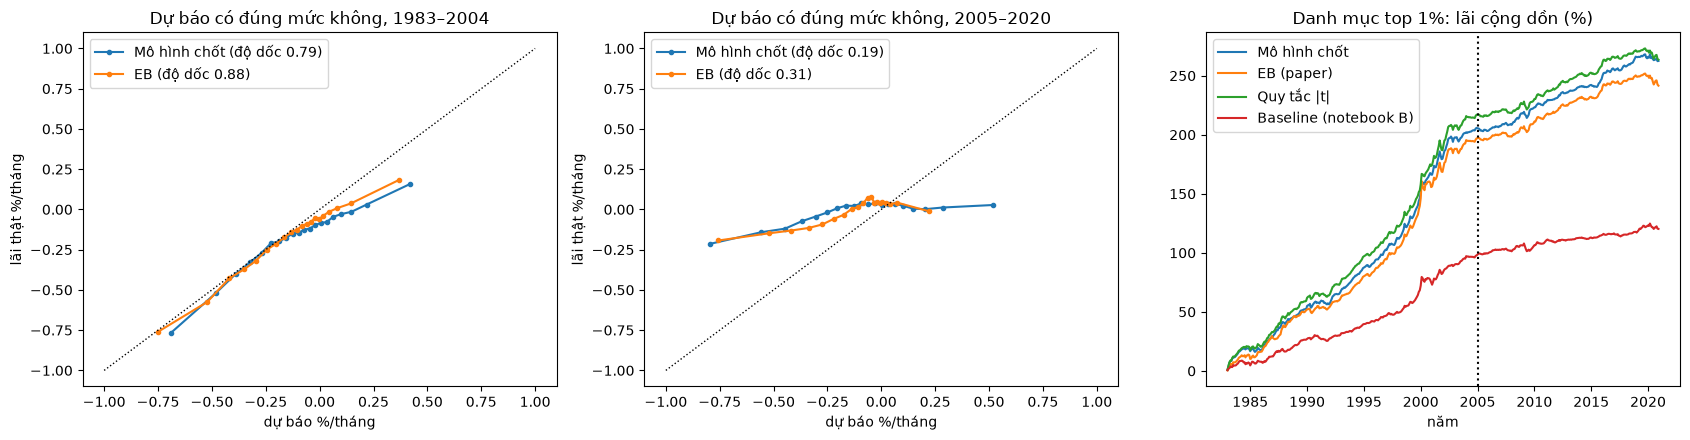

In [14]:
ic_f, ic_e = ev.ic_years(T, P["final"]), ev.ic_years(T, T.eb.values * T.sgn.values)
print("IC theo năm:"); display(pd.DataFrame([ev.ic_test(ic_f, ic_e, *ev.DEV), ev.ic_test(ic_f, ic_e, *ev.HOLD)], index=["dev", "holdout"]).round(3))
# Độ đúng mức như Figure 4-5 của paper: dự báo và lãi thật theo DẤU GỐC của chiến lược, 20 nhóm theo dự báo mỗi năm
Tg = T.assign(y=T.y.values * T.sgn.values)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for i, (lo, hi) in enumerate([ev.DEV, ev.HOLD]):
    for nm, p in [("Mô hình chốt", P["final"] * T.sgn.values), ("EB", T.eb.values)]:
        c = ev.calib_bins(Tg, p, lo, hi); ax[i].plot(c.f, c.y, "o-", ms=3, label=f"{nm} (độ dốc {np.polyfit(c.f, c.y, 1)[0]:.2f})")
    ax[i].plot([-1, 1], [-1, 1], "k:", lw=1); ax[i].set(title=f"Dự báo có đúng mức không, {lo}–{hi}", xlabel="dự báo %/tháng", ylabel="lãi thật %/tháng"); ax[i].legend()
for kk, R in port.items():
    ax[2].plot(R[1].year + (R[1].month - 1) / 12, R[1].ret.cumsum(), label=kk)
ax[2].axvline(2005, color="k", ls=":"); ax[2].set(title="Danh mục top 1%: lãi cộng dồn (%)", xlabel="năm"); ax[2].legend()
plt.tight_layout(); plt.show()

## Kết luận (mô hình chốt = seed 1, checkpoint `checkpoints/final_s1/`)

| Sharpe top 1 / 5 / 10% | Dev 1983–2004 | Holdout 2005–2020 |
|---|---|---|
| Baseline (notebook B) | 1,34 / 1,23 / 1,16 | 0,61 / 0,51 / 0,54 |
| **Mô hình chốt** | **1,95 / 1,95** / 1,82 | **1,11 / 0,88 / 0,88** |
| EB (paper) | 1,55 / 1,91 / 1,86 | 0,82 / 0,78 / 0,86 |
| Quy tắc \|t\| (không mô hình) | 1,95 / 1,99 / 1,85 | 0,84 / 0,75 / 0,83 |

- **So với EB:** hơn ở 5/6 ô. Top 1% hơn có ý nghĩa ở cả dev (HAC p = 0,032) và holdout (p = 0,028). Dev top 10% thấp hơn 0,05 (p = 0,32, tức ngang).
- **So với baseline:** hơn rõ ở dev (p ≤ 0,004); holdout cao hơn (p 0,06–0,08).
- **IC:** dev 0,151 so với 0,188 của EB (thấp hơn, p = 0,013); holdout 0,043 so với 0,021.
- **Độ đúng mức** (cách của paper, dấu gốc): độ dốc dev 0,79 (EB 0,88); holdout 0,19 (EB 0,31). Mô hình xếp hạng tốt hơn, EB đoán độ lớn chuẩn hơn.
- **Họ nhiễu Ticker** (không học, chỉ suy luận): mô hình chọn 0,19% Ticker vào top 1% (EB 0%; chọn bừa 43,5%).
- **Chọn seed:** seed 1 có dev muộn 1995–2004 cao nhất trong 6 seed (bảng ở Bước 10).

So sánh đầy đủ với EB theo 4 cách chấm của paper, có hình: `docs/7_COMPARE_WITH_EB.md`.